<a href="https://colab.research.google.com/github/joelya9-design/Yield-curve/blob/main/Credit_Spread_Sector_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#import dictionairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas_datareader as pdr
from datetime import datetime

In [27]:
#download the data from fred and create variables for each Bond index

#create variables for the start and end of time period analysed
start=datetime(2021,10,14)
end=datetime(2026,10,14)
#investement grade global index
ig_global=pdr.DataReader('BAMLC0A0CM','fred',start,end).dropna()
#investment grade tech
ig_tech=pdr.DataReader('BAMLC1A0C13Y','fred',start,end).dropna()
#investment grade energie
ig_industrials=pdr.DataReader('BAMLC0A1CAAA','fred',start,end).dropna()


print(ig_global,hy_global,ig_tech,ig_industrials)

            BAMLC0A0CM
DATE                  
2023-10-16        1.27
2023-10-17        1.27
2023-10-18        1.29
2023-10-19        1.31
2023-10-20        1.33
...                ...
2026-10-06        0.83
2026-10-07        0.82
2026-10-08        0.82
2026-10-09        0.83
2026-10-12        0.83

[783 rows x 1 columns]             BAMLH0A0HYM2
DATE                    
2023-10-16          4.27
2023-10-17          4.25
2023-10-18          4.32
2023-10-19          4.37
2023-10-20          4.52
...                  ...
2026-10-06          3.03
2026-10-07          3.09
2026-10-08          3.15
2026-10-09          3.11
2026-10-12          3.11

[784 rows x 1 columns]             BAMLC1A0C13Y
DATE                    
2023-10-16          0.94
2023-10-17          0.95
2023-10-18          0.97
2023-10-19          0.97
2023-10-20          0.99
...                  ...
2026-10-06          0.55
2026-10-07          0.55
2026-10-08          0.54
2026-10-09          0.54
2026-10-12          0.54

[7

In [28]:
#combine all variables into one dataframe
#axis=1 puts the series into columns
credit_spreads=pd.concat([ig_global,ig_tech,ig_industrials],axis=1).dropna()
#create column names using .columns function
credit_spreads.columns=['IG Global','IG Tech','IG Industrials']
#use .resample function to pull just the average for each month
credit_spreads_monthly=credit_spreads.resample('ME').mean()

print(credit_spreads_monthly)

            IG Global   IG Tech  IG Industrials
DATE                                           
2023-10-31   1.305000  0.970833        0.484167
2023-11-30   1.213182  0.917727        0.418636
2023-12-31   1.072857  0.794762        0.381905
2024-01-31   1.027273  0.750000        0.378636
2024-02-29   0.980476  0.679048        0.382857
2024-03-31   0.954286  0.634286        0.380000
2024-04-30   0.920000  0.620455        0.365455
2024-05-31   0.889565  0.572609        0.363043
2024-06-30   0.935714  0.613333        0.404286
2024-07-31   0.934348  0.598696        0.383478
2024-08-31   1.004783  0.650870        0.420870
2024-09-30   0.960952  0.610476        0.371429
2024-10-31   0.855217  0.542609        0.320870
2024-11-30   0.806818  0.510909        0.325455
2024-12-31   0.803500  0.525000        0.334000
2025-01-31   0.822727  0.546818        0.334091
2025-02-28   0.823000  0.514000        0.357000
2025-03-31   0.917619  0.580952        0.412381
2025-04-30   1.105714  0.789524        0

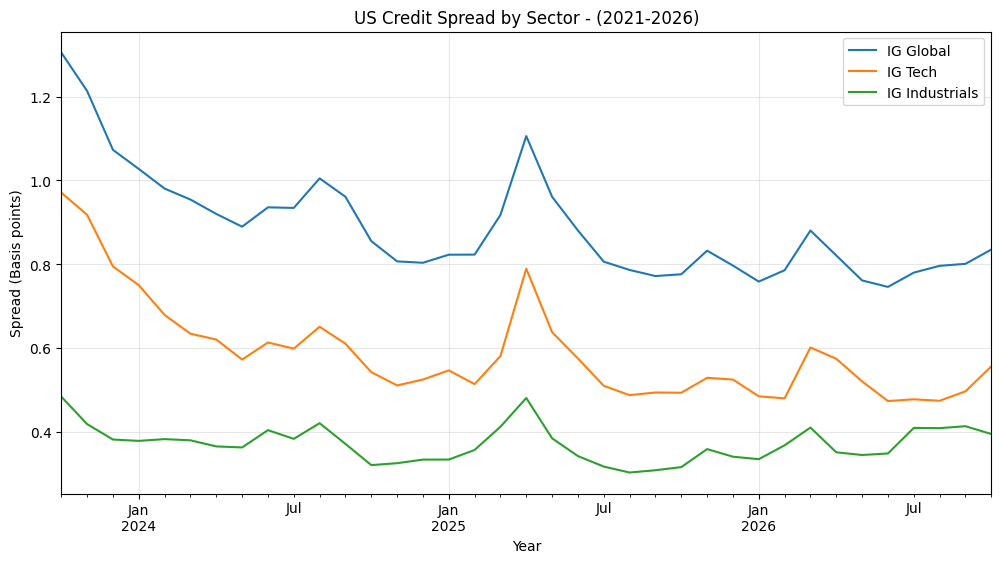

In [29]:
#plot all spreads for each index
credit_spreads_monthly.plot(figsize=(12,6))
plt.title('US Credit Spread by Sector - (2021-2026)')
plt.xlabel('Year')
plt.ylabel('Spread (Basis points)')
plt.grid(True,alpha=0.3)
plt.savefig('credit_spread_index.png',dpi=150,bbox_inches='tight')
plt.show()
